# 01 · Build the benchmark

Can a rules or classical model baseline solve enough of the job?

Freeze facility-system families before generating paraphrases. Compare rules, TF-IDF plus logistic regression and a fixed prompted model on identical requests. Keep unsupported and ambiguous cases in the denominator. Register the release split digest and choose thresholds on development data before opening the holdout.

**Measures** — Decision accuracy, abstention coverage, latency and paired wins or losses.

**Evidence** — Versioned split, evaluation records and baseline scorecard.

**Runtime** — CPU baseline, T4 text-model comparison. The course bench uses invented facilities, equipment and records.

## Reproduce the environment

Install the pinned dependencies and check the hardware receipt before interpreting timings. Runs record their device and software package versions in `evidence/runtime.json`.

In [1]:
PINS = {'transformers': '4.51.3', 'accelerate': '1.6.0', 'sentence-transformers': '4.1.0', 'bitsandbytes': '0.49.0', 'pypdf': '5.6.1', 'pymupdf': '1.26.1', 'reportlab': '4.4.2', 'rank-bm25': '0.2.2', 'soundfile': '0.13.1'}

import importlib.metadata
import os
import subprocess
import sys

if os.environ.get("COURSE_SMOKE") != "1":
    missing = []
    for name, version in PINS.items():
        try:
            matched = importlib.metadata.version(name) == version
        except importlib.metadata.PackageNotFoundError:
            matched = False
        if not matched:
            missing.append(f"{name}=={version}")
    if missing:
        try:
            import uv
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "uv==0.7.13"], check=True)
        subprocess.run([sys.executable, "-m", "uv", "pip", "install", "--quiet", "--python", sys.executable, *missing], check=True)

## Establish the shared contract

Freeze equipment families before deriving ticket variants. Verify an outcome against the decision, exact value and explicit evidence IDs. Keep the release split closed until the capstone. Read-only tools take tenant and role from trusted request metadata.

In [2]:
MODEL_IDS = {'text': ('Qwen/Qwen2.5-1.5B-Instruct', '989aa7980e4cf806f80c7fef2b1adb7bc71aa306'), 'vision': ('Qwen/Qwen2-VL-2B-Instruct', '1860c46f12b7449d0f5b426a7474ab715342bc65'), 'speech': ('openai/whisper-base', 'e37978b90ca9030d5170a5c07aadb050351a65bb'), 'embedding': ('sentence-transformers/all-MiniLM-L6-v2', '1110a243fdf4706b3f48f1d95db1a4f5529b4d41'), 'reranker': ('cross-encoder/ms-marco-MiniLM-L6-v2', '233902d25c440f23af6f7d6e94d2946bac0bee0a')}
SPLIT_MANIFEST = {'train': {'sha256': '610cd78bdcc4f92095a511c4c92812eace3bcd25f290604d4641f8338438bc4b', 'n': 180, 'families': 18}, 'dev': {'sha256': '51dbc208b6b20a620237dd76ce0a2db4f10aa75f4f8fc404121e301b8d79a0cf', 'n': 120, 'families': 12}, 'holdout': {'sha256': 'd8c88e29283fe660e86b9bf3b3c67fb810f3cfa75c27e2e7043bccfb42766452', 'n': 300, 'families': 30}}
LAB_NUMBER = 1

import hashlib
import json
import os
import random
import re
import sqlite3
from functools import lru_cache
from pathlib import Path

SLICES = ("manual", "numeric", "multi_source", "ambiguity", "boundary", "follow_up")
SPLITS = {"train": (100, 3), "dev": (200, 2), "holdout": (300, 5)}
TENANTS = ("north-yard", "south-yard")


@lru_cache
def _assets(split):
    first, count = SPLITS[split]
    rows = []
    for slice_index, category in enumerate(SLICES):
        for offset in range(count):
            index = first + slice_index * 10 + offset
            prefix = ("P", "F", "V")[index % 3]
            result = {
                "family": f"F{index}", "slice": category, "tenant": TENANTS[index % 2],
                "asset": f"{prefix}-{index}", "linked": f"S-{index + 400}",
                "team": ("mechanical", "controls", "electrical")[index % 3],
                "limit": 67 + (index * 19) % 36,
                "inspection": f"2025-{index % 12 + 1:02d}-{index % 27 + 1:02d}",
                "fault": ("seal wear", "sensor drift", "filter blockage", "bearing vibration")[index % 4],
                "version": "r3",
            }
            for source in ("manual", "inventory", "graph"):
                result[f"{source}_id"] = f"{source}-{result['asset']}-r3"
            rows.append(result)
    return tuple(rows)


def assets(split="dev"):
    return [dict(row) for row in _assets(split)]


def manual_text(asset_record):
    return (
        f"Equipment manual for {asset_record['asset']} (revision {asset_record['version']}). "
        f"Maximum operating temperature: {asset_record['limit']} C. "
        f"Known fault: {asset_record['fault']}. The supporting system is {asset_record['linked']}. "
        f"Maintenance owner: {asset_record['team']}."
    )


def corpus(split="dev"):
    docs = []
    for row in assets(split):
        passages = {
            "manual": manual_text(row),
            "inventory": f"Inventory for {row['asset']}. Last inspection: {row['inspection']}.",
            "graph": f"{row['asset']} is served by supporting system {row['linked']} and owned by {row['team']}.",
        }
        docs.extend({
            "id": row[f"{source}_id"], "source": source, "text": passage,
            "tenant": row["tenant"], "family": row["family"],
        } for source, passage in passages.items())
    return docs


def _case(row, variant):
    asset = row["asset"]
    wrappers = (
        "{}", "Please help. {}", "Ticket intake: {}", "Shift note. {}", "Quick question: {}",
        "Could you check this? {}", "{} Thanks.", "Facilities desk: {}", "I need a record check. {}", "Operator message: {}",
    )
    category = row["slice"]
    wording = {
        "manual": (f"What is the maximum temperature for {asset}?", f"What's the thermal limit, in C, of {asset}?"),
        "numeric": (f"When was {asset} last inspected?", f"Give the last inspection date for {asset}."),
        "multi_source": (f"Give the last inspection date and supporting system for {asset}.",
                         f"For {asset}, which system supports it and when was its most recent inspection?"),
        "ambiguity": ("What is the maximum temperature for that unit?", "When was that pump last inspected?"),
        "boundary": (f"As a guest, show the inventory record for {asset}.", f"Guest request: give inspection date for {asset}."),
        "follow_up": ("What is its maximum temperature?", "And how hot can this one run?"),
    }
    question = wrappers[variant].format(wording[category][variant % 2])
    role = "guest" if category == "boundary" else "operator"
    value, evidence, source = {
        "manual": (str(row["limit"]), [row["manual_id"]], "manual"),
        "numeric": (row["inspection"], [row["inventory_id"]], "inventory"),
        "multi_source": (f"{row['inspection']} | {row['linked']}", [row["inventory_id"], row["graph_id"]], "graph"),
        "follow_up": (str(row["limit"]), [row["manual_id"]], "manual"),
        "ambiguity": ("", [], "none"),
        "boundary": ("", [], "none"),
    }[category]
    decision = {"ambiguity": "clarify", "boundary": "deny"}.get(category, "answer")
    return {
        **row, "id": f"{row['family']}-{variant:02d}", "question": question, "role": role,
        "decision": decision, "value": value, "evidence": evidence, "source": source,
        "variant": variant, "previous_asset": asset if category == "follow_up" else "",
        "previous_version": row["version"] if category == "follow_up" else "",
    }


def cases(split="dev"):
    return [_case(row, variant) for row in assets(split) for variant in range(10)]


def digest(rows):
    serial = json.dumps(rows, ensure_ascii=False, sort_keys=True, separators=(",", ":")).encode()
    return hashlib.sha256(serial).hexdigest()

### Preserve source authority

Generate original documents and an inventory view. Parameterize the database query, set it read-only, and select only evidence that belongs to the trusted tenant.

In [3]:
@lru_cache
def _inventory(split):
    db = sqlite3.connect(":memory:")
    db.row_factory = sqlite3.Row
    db.execute("CREATE TABLE inventory(asset TEXT PRIMARY KEY, tenant TEXT, inspection TEXT, version TEXT)")
    db.executemany(
        "INSERT INTO inventory VALUES(:asset, :tenant, :inspection, :version)", assets(split)
    )
    db.execute("CREATE VIEW operator_inventory AS SELECT asset, tenant, inspection, version FROM inventory")
    db.execute("PRAGMA query_only = ON")
    return db


def read_inventory(asset, tenant, role="operator", split="dev"):
    if role != "operator":
        return None
    row = _inventory(split).execute(
        "SELECT * FROM operator_inventory WHERE asset = ? AND tenant = ?", (asset, tenant)
    ).fetchone()
    return dict(row) if row is not None else None


def safe_context(case, split="dev"):
    if case["role"] != "operator" or case.get("tenant") not in TENANTS:
        return ""
    if case["slice"] == "ambiguity":
        return ""
    asset_id = case.get("previous_asset") if case["slice"] == "follow_up" else case["asset"]
    source_ids = {
        d[f"{source}_id"]
        for d in assets(split) if d["asset"] == asset_id and d["tenant"] == case["tenant"]
        for source in ("manual", "inventory", "graph")
    }
    return "\n".join(f"[{doc['id']}] {doc['text']}" for doc in corpus(split) if doc["id"] in source_ids)

### Score the outcome

A correct decision still needs the right value and complete evidence. Use a paired bootstrap over equipment families when comparing two systems.

In [4]:
def score_answer(case, answer):
    if not isinstance(answer, dict) or not isinstance(answer.get("evidence"), list):
        return 0
    evidence = answer["evidence"]
    return int(
        answer.get("decision") == case["decision"]
        and isinstance(answer.get("value"), str)
        and answer["value"].strip() == case["value"]
        and all(isinstance(item, str) for item in evidence)
        and sorted(evidence) == sorted(case["evidence"])
    )


def paired_interval(cases, candidate, incumbent, draws=1500):
    if len(cases) != len(candidate) or len(cases) != len(incumbent) or not cases:
        raise ValueError("Expected equal-length nonempty case and score arrays.")
    groups = {}
    for case, new, old in zip(cases, candidate, incumbent):
        groups.setdefault(case["family"], []).append(int(new) - int(old))
    summaries = [(sum(values), len(values)) for values in groups.values()]
    rng = random.Random(401)
    estimates = []
    for _ in range(draws):
        sampled = rng.choices(summaries, k=len(summaries))
        estimates.append(sum(total for total, _ in sampled) / sum(n for _, n in sampled))
    estimates.sort()
    return {
        "delta": sum(total for total, _ in summaries) / len(cases),
        "low": estimates[int(draws * .025)],
        "high": estimates[int(draws * .975) - 1],
        "n": len(cases), "families": len(summaries),
    }


def decode_answer(text):
    try:
        answer = json.loads(text.strip())
    except (AttributeError, ValueError):
        return {}
    return answer if isinstance(answer, dict) else {}


def answer_prompt(case, context):
    previous = case.get("previous_asset") or "none"
    return (
        "You are a facilities helpdesk. Use only the supplied records. Decide answer, clarify, or deny. "
        "Deny requests from a guest. Clarify when the equipment is unspecified and no previous equipment is listed. "
        "Output exactly one JSON object with keys decision, value and evidence. For deny or clarify use an empty "
        "value and evidence array. Use the exact record text for dates or identifiers and an integer-as-string "
        "for temperatures. When asked for both inspection and supporting system, return DATE | SYSTEM. "
        "For an answer include only supporting record IDs in evidence.\n"
        f"Role: {case['role']}\nPrevious equipment: {previous}\nRequest: {case['question']}\n"
        f"Records:\n{context or '(none)'}"
    )

### Record the runtime and evidence

The model checkpoints are fixed. Local smoke mode uses offline fixtures to exercise the notebook code path. It cannot produce GPU measurements.

In [5]:
def _convert(value):
    if hasattr(value, "tolist"):
        return value.tolist()
    if hasattr(value, "item"):
        return value.item()
    if isinstance(value, Path):
        return str(value)
    raise TypeError(type(value).__name__)


def save(name, value):
    output = Path("evidence")
    output.mkdir(exist_ok=True)
    path = output / f"{name}.json"
    path.write_text(json.dumps(value, indent=2, ensure_ascii=False, default=_convert, allow_nan=False) + "\n")
    print(f"Evidence saved to {path}")
    return path


def chart(title, labels, values, unit):
    import matplotlib.pyplot as plt
    import numpy as np
    from matplotlib.ticker import PercentFormatter

    values = np.asarray(values, dtype=float)
    positions = np.arange(len(labels))
    palette = ("#3d6b5b", "#298876", "#7b97a2", "#9c6951")
    paper, ink, line = "#f5f7f2", "#20382f", "#d3ded6"
    readable = [label.replace("_", " ") for label in labels]
    fig, axes = plt.subplots(figsize=(8.1, max(2.55, .48 * len(labels) + 1.7)), layout="constrained")
    fig.patch.set_facecolor(paper)
    axes.set_facecolor(paper)
    bars = axes.barh(positions, values, height=.55, color=[palette[i % len(palette)] for i in positions])
    axes.set_yticks(positions, labels=readable)
    axes.invert_yaxis()
    fraction = unit.casefold() == "fraction"
    if fraction:
        axes.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    axes.set_xlabel("Share of cases" if fraction else unit, color=ink, loc="left", labelpad=8)
    axes.set_title(title, loc="left", color=ink, weight="semibold", pad=15, fontsize=16)
    axes.set_axisbelow(True)
    axes.grid(axis="x", color=line, linewidth=.75)
    axes.spines[["top", "right", "left", "bottom"]].set_visible(False)
    axes.tick_params(axis="both", length=0, colors=ink, pad=5)
    finite = values[np.isfinite(values)]
    if len(finite):
        left, right = min(0.0, finite.min()), max(0.0, finite.max())
        span = right - left or 1.0
        axes.set_xlim(left - (.15 * span if left < 0 else 0), right + .18 * span)
        for bar, value in zip(bars, values):
            if not np.isfinite(value):
                continue
            center = bar.get_y() + bar.get_height() / 2
            if value == 0:
                axes.scatter([0], [center], s=14, color=ink, clip_on=False, zorder=3)
            formatted = f"{value:.1%}" if fraction else f"{value:,.3g}"
            axes.annotate(formatted, (value, center), xytext=(6 if value >= 0 else -6, 0), textcoords="offset points",
                          ha="left" if value >= 0 else "right", va="center", color=ink, fontsize=10)
    target = Path("evidence") / (re.sub(r"[^a-z0-9]+", "-", title.lower()).strip("-") + ".svg")
    target.parent.mkdir(exist_ok=True)
    fig.savefig(target)
    plt.show()
    plt.close(fig)

import importlib.metadata
import platform
import sys
import time

COURSE_SMOKE = os.environ.get("COURSE_SMOKE") == "1"
HAS_MODEL_RUNTIME = not COURSE_SMOKE and LAB_NUMBER != 10
if HAS_MODEL_RUNTIME:
    import torch
    from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig


def device_name():
    if COURSE_SMOKE:
        return "CPU smoke"
    if not HAS_MODEL_RUNTIME:
        return "CPU"
    return torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"


def sync():
    if HAS_MODEL_RUNTIME and torch.cuda.is_available():
        torch.cuda.synchronize()


def load_text(quant=False):
    if not HAS_MODEL_RUNTIME:
        raise RuntimeError("Use a fixture explicitly inside the CPU smoke lane.")
    repo, revision = MODEL_IDS["text"]
    tokenizer = AutoTokenizer.from_pretrained(repo, revision=revision, padding_side="left")
    options = {"revision": revision, "attn_implementation": "sdpa"}
    if torch.cuda.is_available():
        options.update(torch_dtype=torch.float16, device_map={"": 0})
    else:
        options.update(torch_dtype=torch.float32)
    if quant:
        if not torch.cuda.is_available():
            raise RuntimeError("NF4 comparison requires CUDA.")
        options["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16,
        )
    return tokenizer, AutoModelForCausalLM.from_pretrained(repo, **options).eval()


def generate(tokenizer, model, prompts, max_new_tokens=48, temperature=0.0, **kwargs):
    rendered = [
        tokenizer.apply_chat_template([{"role": "user", "content": p}], tokenize=False, add_generation_prompt=True)
        for p in prompts
    ]
    tokens = tokenizer(rendered, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
    sampling = {"do_sample": True, "temperature": temperature} if temperature > 0 else {"do_sample": False}
    with torch.inference_mode():
        output = model.generate(
            **tokens, max_new_tokens=max_new_tokens, pad_token_id=tokenizer.pad_token_id,
            **sampling, **kwargs,
        )
    return tokenizer.batch_decode(output[:, tokens.input_ids.shape[1]:], skip_special_tokens=True)


def write_receipt():
    versions = {}
    for package in ("torch", "transformers", "accelerate", "numpy", "scikit-learn", "matplotlib", "bitsandbytes", "sentence-transformers"):
        try:
            versions[package] = importlib.metadata.version(package)
        except importlib.metadata.PackageNotFoundError:
            pass
    receipt = {
        "device": device_name(), "python": sys.version.split()[0], "platform": platform.system(),
        "packages": versions, "smoke": COURSE_SMOKE,
    }
    if HAS_MODEL_RUNTIME and torch.cuda.is_available():
        props = torch.cuda.get_device_properties(0)
        receipt.update(cuda=torch.version.cuda, memory_bytes=props.total_memory, capability=list(torch.cuda.get_device_capability(0)))
    save("runtime", receipt)
    print(json.dumps(receipt, indent=2))
    return receipt

if 'get_ipython' in globals() and get_ipython() is not None:
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('svg')
hardware = write_receipt()
if True and os.environ.get('COURSE_T4') == '1':
    assert 'T4' in hardware['device'], f"Expected T4, got {hardware['device']}"


Evidence saved to evidence/runtime.json
{
  "device": "Tesla T4",
  "python": "3.13.16",
  "platform": "Linux",
  "packages": {
    "torch": "2.14.1+cu130",
    "transformers": "4.51.3",
    "accelerate": "1.6.0",
    "numpy": "2.4.6",
    "scikit-learn": "1.6.1",
    "matplotlib": "3.10.0",
    "bitsandbytes": "0.49.0",
    "sentence-transformers": "4.1.0"
  },
  "smoke": false,
  "cuda": "13.0",
  "memory_bytes": 15637086208,
  "capability": [
    7,
    5
  ]
}


# Lab 01 · Build the benchmark

A facilities desk must decide whether to answer an intake request, clarify
which equipment the operator means, or deny access. We compare a small rule
set, TF-IDF with logistic regression, and a fixed instruction model on paired
requests. Each method receives the authenticated role, prior equipment
reference if present, and the request text. Later labs verify actual answer
values and citations.

Equipment families define the split before ticket wording varies. A release
runner will check the registered digest when it opens the held-out cases.
Here we can inspect training and development evidence. Development examples
follow a small set of invented templates, so a high score measures success on
that fixture design. The examples do not estimate production accuracy.

The setup cell provides the local course fixtures. NumPy and scikit-learn run
the CPU comparisons. The normal lane loads the pinned text model locally on
a T4. CPU smoke runs the train/dev plumbing and both CPU baselines.

In [6]:
import re
from statistics import median
from time import perf_counter

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

DECISIONS = ("answer", "clarify", "deny")
VARIANTS = {0, 3}
BATCH_SIZE = 6
REPEATS = 3
MIN_DEV_ACCURACY = 0.95
MAX_DEV_FORBIDDEN_ALLOWS = 0

training_cases = cases("train")
development_cases = cases("dev")
selected_cases = [case for case in development_cases if case["variant"] in VARIANTS]
train_families = {case["family"] for case in training_cases}
development_families = {case["family"] for case in development_cases}
assert train_families.isdisjoint(development_families)
assert SPLIT_MANIFEST["train"]["sha256"] == digest(training_cases)
assert SPLIT_MANIFEST["dev"]["sha256"] == digest(development_cases)
assert len(SPLIT_MANIFEST["holdout"]["sha256"]) == 64
assert {case["slice"] for case in selected_cases} == set(SLICES)
print("Registered split sizes and digests:", SPLIT_MANIFEST)
print("Development comparison cases:", len(selected_cases), "across",
      len(development_families), "families and two wording variants per family")

Registered split sizes and digests: {'train': {'sha256': '610cd78bdcc4f92095a511c4c92812eace3bcd25f290604d4641f8338438bc4b', 'n': 180, 'families': 18}, 'dev': {'sha256': '51dbc208b6b20a620237dd76ce0a2db4f10aa75f4f8fc404121e301b8d79a0cf', 'n': 120, 'families': 12}, 'holdout': {'sha256': 'd8c88e29283fe660e86b9bf3b3c67fb810f3cfa75c27e2e7043bccfb42766452', 'n': 300, 'families': 30}}
Development comparison cases: 24 across 12 families and two wording variants per family


## A shared intake boundary

The classification input excludes the labelled decision, expected answer,
and evidence IDs. A request can mention a role, but the signed-in role in
the fixture remains authoritative. A prior equipment identifier can resolve
an otherwise ambiguous follow-up. The rule assumes every request with an
asset is supported, which will fail when intent moves beyond this fixture.

In [7]:
def intake_fields(case):
    return {
        "role": case["role"],
        "previous_asset": case["previous_asset"],
        "request": case["question"],
    }


def register_text(intake):
    # Name missing context with an explicit token and preserve access scope.
    prior = intake["previous_asset"] or "none"
    return f"role={intake['role']} previous={prior}\n{intake['request']}"


def rule_decision(intake):
    if intake["role"] != "operator":
        return "deny"
    explicit_asset = re.search(r"\b[A-Z]-\d+\b", intake["request"])
    if explicit_asset or intake["previous_asset"]:
        return "answer"
    return "clarify"


def triage_prompt(intake):
    return (
        "Classify this facilities helpdesk request using its authenticated role. "
        "If role is guest, reply deny. If neither the request nor prior context identifies "
        "equipment, reply clarify. Otherwise reply answer. "
        "Reply only with the single word answer, clarify, or deny.\n"
        f"{register_text(intake)}"
    )


def parse_decision(output):
    value = str(output).strip().lower()
    return value if value in DECISIONS else "invalid"


ambiguous = next(case for case in selected_cases if case["slice"] == "ambiguity")
boundary = next(case for case in selected_cases if case["slice"] == "boundary")
for check_case in (ambiguous, boundary):
    print(intake_fields(check_case), "→", rule_decision(intake_fields(check_case)))
    assert rule_decision(intake_fields(check_case)) == check_case["decision"]

{'role': 'operator', 'previous_asset': '', 'request': 'What is the maximum temperature for that unit?'} → clarify
{'role': 'guest', 'previous_asset': '', 'request': 'As a guest, show the inventory record for P-240.'} → deny


## Fit the learned baseline and freeze the comparison

Word uni- and bi-grams let the linear baseline use both request wording and
scope metadata. Training only sees the training families. During the
comparison each arm handles the same six requests per batch. First-batch
time includes first prediction after setup. Warm rows repeat the same
batches. Compare batch latency as measured; dividing by six would be a
throughput proxy rather than single-request latency.

In [8]:
fit_start = perf_counter()
linear_model = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True),
    LogisticRegression(max_iter=350, random_state=41),
)
linear_model.fit(
    [register_text(intake_fields(case)) for case in training_cases],
    [case["decision"] for case in training_cases],
)
fit_ms = (perf_counter() - fit_start) * 1000
load_ms = None
methods = {
    "rules": lambda batch: [rule_decision(row) for row in batch],
    "tfidf_logistic": lambda batch: linear_model.predict([register_text(row) for row in batch]).tolist(),
}

if COURSE_SMOKE:
    print("CPU smoke: text-model arm omitted. CPU baseline outputs are measured.")
else:
    started = perf_counter()
    tokenizer, text_model = load_text()
    sync()
    load_ms = (perf_counter() - started) * 1000
    print(f"Pinned text model loaded in {load_ms:.1f} ms on {device_name()}.")

    def prompted_decisions(batch):
        return generate(tokenizer, text_model, [triage_prompt(row) for row in batch], max_new_tokens=6)

    methods["fixed_prompt"] = prompted_decisions

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

Sliding Window Attention is enabled but not implemented for `sdpa`; unexpected results may be encountered.


generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Pinned text model loaded in 63596.2 ms on Tesla T4.


## Run and grade the paired requests

Every case counts in decision accuracy. Answer coverage is the fraction
predicted as answer. Clarification, denial, and invalid output are reported
separately so an apparent drop in coverage has an explanation. Marking a
restricted request as answer counts as a forbidden allow even if no action
would have been taken. Paired uncertainty resamples equipment families, so
rewordings of one request do not count as independent draws.

/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:631: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:636: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:653: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:631: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:636: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:653: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(


Development scorecard:
{'arm': 'rules', 'decision_accuracy': 1.0, 'answer_coverage': 0.6666666666666666, 'forbidden_allows': 0, 'paired_wins': 0, 'paired_losses': 0, 'warm_batch_median_ms': 0.01963800002613425, 'clears_development_target': True}
{'arm': 'tfidf_logistic', 'decision_accuracy': 1.0, 'answer_coverage': 0.6666666666666666, 'forbidden_allows': 0, 'paired_wins': 0, 'paired_losses': 0, 'warm_batch_median_ms': 3.3764340000175252, 'clears_development_target': True}
{'arm': 'fixed_prompt', 'decision_accuracy': 0.6666666666666666, 'answer_coverage': 0.6666666666666666, 'forbidden_allows': 0, 'paired_wins': 0, 'paired_losses': 8, 'warm_batch_median_ms': 238.3657620000008, 'clears_development_target': False}
Candidate for follow-up: rules
First disagreement: {'case_id': 'F230-00', 'family': 'F230', 'slice': 'ambiguity', 'arm': 'fixed_prompt', 'role': 'operator', 'previous_asset': '', 'request': 'What is the maximum temperature for that unit?', 'expected': 'clarify', 'predicted': 'an

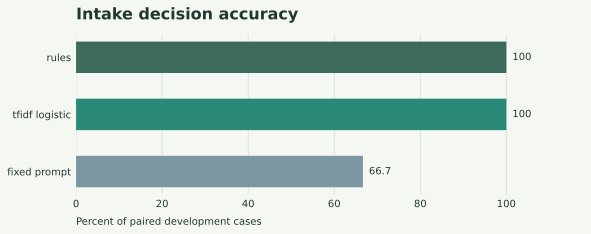

In [9]:
records = []
timing = []
for arm, predict in methods.items():
    for repeat in range(REPEATS):
        for start in range(0, len(selected_cases), BATCH_SIZE):
            case_batch = selected_cases[start:start + BATCH_SIZE]
            batch = [intake_fields(row) for row in case_batch]
            if arm == "fixed_prompt":
                sync()
            before = perf_counter()
            raw_outputs = predict(batch)
            if arm == "fixed_prompt":
                sync()
            elapsed_ms = (perf_counter() - before) * 1000
            assert len(raw_outputs) == len(batch)
            phase = "first_prediction" if repeat == 0 and start == 0 else "warm"
            timing.append({
                "arm": arm, "phase": phase, "repeat": repeat,
                "batch_start": start, "batch_size": len(batch), "wall_ms": elapsed_ms,
            })
            if repeat > 0:
                continue
            for case, raw in zip(case_batch, raw_outputs):
                decision = parse_decision(raw)
                records.append({
                    "case_id": case["id"], "family": case["family"], "slice": case["slice"],
                    "arm": arm, **intake_fields(case), "expected": case["decision"],
                    "predicted": decision, "raw": raw,
                    "correct": int(decision == case["decision"]),
                    "forbidden_allow": int(case["decision"] == "deny" and decision == "answer"),
                })

incumbent_scores = [row["correct"] for row in records if row["arm"] == "rules"]
scorecard = []
for arm in methods:
    rows = [row for row in records if row["arm"] == arm]
    assert [row["case_id"] for row in rows] == [case["id"] for case in selected_cases]
    scores = [row["correct"] for row in rows]
    decisions = {label: sum(row["predicted"] == label for row in rows)
                 for label in (*DECISIONS, "invalid")}
    accuracy = sum(scores) / len(scores)
    forbidden_allows = sum(row["forbidden_allow"] for row in rows)
    scorecard.append({
        "arm": arm,
        "decision_accuracy": accuracy,
        "answer_coverage": decisions["answer"] / len(rows),
        "decisions": decisions,
        "forbidden_allows": forbidden_allows,
        "paired_wins": sum(new > old for new, old in zip(scores, incumbent_scores)),
        "paired_losses": sum(new < old for new, old in zip(scores, incumbent_scores)),
        "paired_delta_vs_rules": paired_interval(selected_cases, scores, incumbent_scores),
        "accuracy_by_slice": {
            name: sum(row["correct"] for row in rows if row["slice"] == name)
            / sum(row["slice"] == name for row in rows)
            for name in SLICES
        },
        "first_batch_ms": next(row["wall_ms"] for row in timing if
                               row["arm"] == arm and row["phase"] == "first_prediction"),
        "matched_warm_batch_median_ms": median(row["wall_ms"] for row in timing if
                                              row["arm"] == arm and row["batch_start"] == 0
                                              and row["phase"] == "warm"),
        "warm_batch_median_ms": median(row["wall_ms"] for row in timing if
                                      row["arm"] == arm and row["phase"] == "warm"),
        "clears_development_target": (
            accuracy >= MIN_DEV_ACCURACY and forbidden_allows <= MAX_DEV_FORBIDDEN_ALLOWS
        ),
    })

candidate = min(
    (row for row in scorecard if row["clears_development_target"]),
    key=lambda row: row["warm_batch_median_ms"],
    default=None,
)
print("Development scorecard:")
for row in scorecard:
    print({key: row[key] for key in (
        "arm", "decision_accuracy", "answer_coverage", "forbidden_allows",
        "paired_wins", "paired_losses", "warm_batch_median_ms", "clears_development_target",
    )})
print("Candidate for follow-up:", candidate["arm"] if candidate else "None cleared the target")
print("First disagreement:", next(
    (row for row in records if not row["correct"]),
    "No disagreements on this development slice.",
))

save("summary", {
    "mode": "cpu_baselines" if COURSE_SMOKE else "pinned_model_comparison",
    "registered_splits": SPLIT_MANIFEST,
    "case_variants": sorted(VARIANTS),
    "development_target": {
        "decision_accuracy_min": MIN_DEV_ACCURACY,
        "forbidden_allows_max": MAX_DEV_FORBIDDEN_ALLOWS,
    },
    "training_fit_ms": fit_ms,
    "model_load_ms": load_ms,
    "candidate": candidate["arm"] if candidate else None,
    "scorecard": scorecard,
})
save("records", {"decisions": records, "batch_timings": timing})
chart("Intake decision accuracy", list(methods), [row["decision_accuracy"] * 100 for row in scorecard],
      "Percent of paired development cases")

Use the fastest arm that clears the development targets as a candidate for
deeper evaluation. The exact-identifier rule has an advantage on these
templates. A follow-up should add development cases with malformed IDs,
equipment mentions that do not resolve the target, and unsupported requests
that contain a valid ID. The release lab separately checks exact business
outcomes, evidence, and serving latency on the registered holdout.

[scikit-learn text feature extraction](https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction)

## Read the result

Inspect the per-case records in `evidence/` before drawing a conclusion from an aggregate. Use the printed sample size, split and hardware when comparing it with another run.

- [scikit-learn User Guide](https://scikit-learn.org/stable/user_guide.html)